# Pragmatic Bayes and bounded frequentism: a walk-through

**Question.** When data are scarce and the signal cannot be negative, which do you trust:
a Bayesian answer that is best on average, or a frequentist answer that is built to hold
for every possible truth? Both are measured here on one simulator.

**Headline results** (± is one Monte Carlo standard error):

- A neural posterior has almost the same Bayes risk as the exact grid posterior
  (2.727 ± 0.046 vs 2.719 ± 0.046; paired difference on the same draws +0.008 ± 0.004) and
  is about 960 times faster.
- The equal-tailed credible interval ($\alpha=0.1$) covers the truth 94.6% of the time on
  average over the prior. That matches the 94.7% of posterior probability the intervals hold
  on average (most start at the point mass at $\mu=0$), as a correct posterior must. At fixed
  signals between 3 and 8.5, though, it covers only 79–82% ($b=3$, $\varepsilon=1$), and
  never at $\mu=10$.
- Calibrated profile-likelihood and WALDO confidence sets stay above the 0.885 pass threshold
  at 300 random points off the calibration nodes (lowest 0.897 ± 0.005 and 0.895 ± 0.005).
  Calibrated at $\varepsilon=1$ only, they fail there (lowest 0.855 ± 0.002 and 0.870 ± 0.002).

Read the [README](https://github.com/luisgius/bayes-frequentist#readme) for the full
write-up. This notebook reads the saved results in `results/`; it runs no training or
calibration.

In [1]:
import gzip
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from bayesfreq.config import FULL_CONFIG
from bayesfreq.data_simulator import simulate
from bayesfreq.plotting import set_style

ROOT = Path.cwd() if (Path.cwd() / 'results').exists() else Path.cwd().parent
A = json.loads((ROOT / 'results/path_a.json').read_text())
B_summary = json.loads((ROOT / 'results/path_b.json').read_text())
with gzip.open(ROOT / B_summary['artifacts']['details'], 'rt', encoding='utf-8') as stream:
    B = json.load(stream)
assert not A['diagnostics']['quick'], 'Run full Path A first'
assert B['config']['mc']['n_toys_cov'] == FULL_CONFIG.mc.n_toys_cov, 'Run full Path B first'
assert B['diagnostics']['waldo_model']['kind'] == 'path_a_amortized'
set_style()
def show_saved(name):
    display(Image(filename=str(ROOT / 'figures' / name)))
def metric_string(metric):
    return f"{metric['value']:.4f} ± {metric['mc_se']:.4f}"
print('Results generated at:', A['generated_at'], B['generated_at'])
print('All ± values below are one Monte Carlo SE unless labelled exact.')

Results generated at: 2026-10-20T07:06:39.389335+00:00 2026-10-20T07:12:48.902399+00:00
All ± values below are one Monte Carlo SE unless labelled exact.


## 1. The experiment and the physical bound

Let $\mu$ be a source rate, $b$ the background, and $\varepsilon$ a relative efficiency.
The physical signal domain is $\Theta=[0,10]$. In the full case, both paths use three
independent observations: $n_{\rm on}\sim\mathrm{Pois}(\varepsilon\mu+b)$,
$n_{\rm off}\sim\mathrm{Pois}(5b)$ and
$\log\hat\varepsilon\sim N(\log\varepsilon,0.1^2)$.

The core case knows $b=3$ and $\varepsilon=1$ and has no calibration noise
($\sigma_\varepsilon=0$, so $\hat\varepsilon=1$); only $n_{\rm on}\sim\mathrm{Pois}(\mu+3)$
carries information. The full confidence study checks
$b\in[0.5,10]$ and $\varepsilon\in[e^{-0.2},e^{0.2}]$ on finite grids.
The Bayesian reality prior keeps unbounded positive efficiency support; the confidence box
is an explicit scope of the coverage study, not a change to the simulator.

## 2. One simulator

The reality prior has a 30% atom at $\mu=0$, a 70% log-uniform slab on $[0.1,10]$,
uniform background on $[0.5,10]$, and log-normal efficiency, $\log\varepsilon\sim N(0,0.1^2)$.
The three prior components are independent.
The efficiency prior and the auxiliary measurement are separate random draws.
Below, the observed counts follow the conditional means and variances of a Poisson law.

,count,mean,mean MC SE,variance,variance MC SE,theoretical mean/variance
0,on,4.9882,0.0158,5.0610,0.0524,5.0
1,off,14.9786,0.0274,14.8191,0.1525,15.0


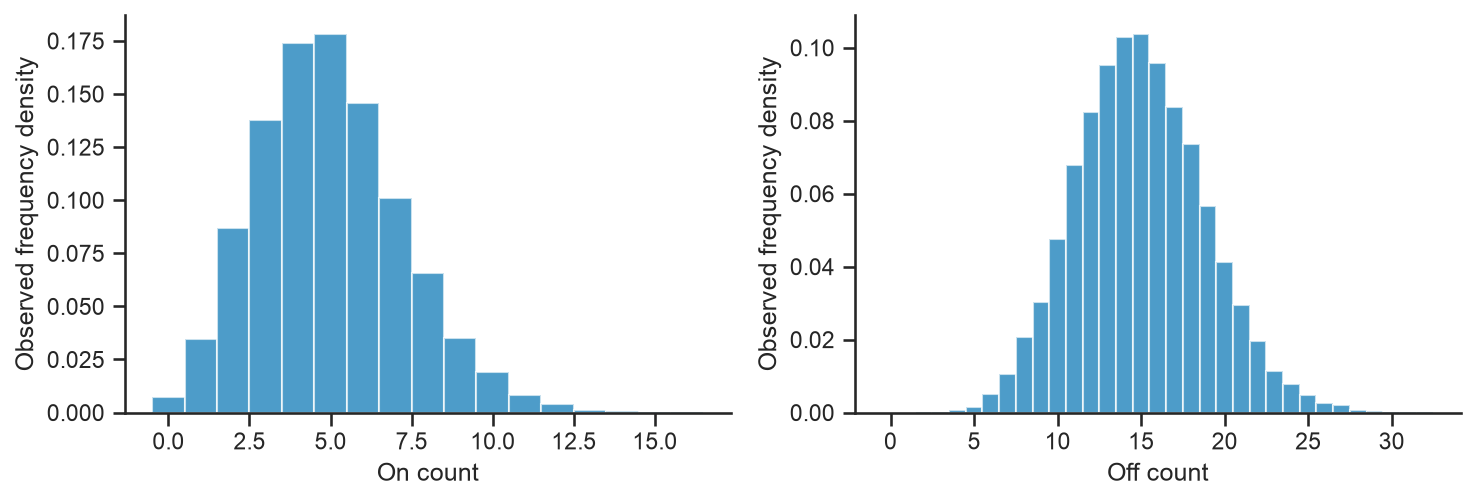

In [2]:
rng = np.random.default_rng(882901)
x = simulate(2., 3., 1., size=20000, rng=rng)
rows = []
for i, theoretical in enumerate((5., 15.)):
    count = len(x)
    rows.append({'count': ('on', 'off')[i], 'mean': x[:, i].mean(),
                 'mean MC SE': np.sqrt(theoretical / count),
                 'variance': x[:, i].var(ddof=1),
                 'variance MC SE': np.sqrt(
                     (theoretical + (2 + 2/(count-1))*theoretical**2)/count),
                 'theoretical mean/variance': theoretical})
display(pd.DataFrame(rows).round(4))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for i, ax in enumerate(axes):
    ax.hist(x[:, i], bins=np.arange(x[:, i].max()+2)-.5, density=True, alpha=.7)
    ax.set(xlabel=('On count', 'Off count')[i], ylabel='Observed frequency density')
fig.tight_layout()
plt.show()

## 3. Path A: Bayes risk and compute cost

Squared Bayes risk averages $(\delta(X)-\mu)^2$ over the reality prior and the data.
The posterior mean minimizes this criterion. The neural model approximates the
reality-prior posterior. Laplace is a local approximation of the same posterior, with
plug-in nuisances. Gamma plug-in is a posterior under a different, diffuse Gamma prior with
no atom at zero, with the background and efficiency fixed at their measured values.
The clipped MLE is a frequentist comparison.
Each error bar below is one Monte Carlo SE. Timing measures batched throughput after warm-up.

,estimator,squared Bayes risk ± SE,paired difference vs grid ± SE,inference µs/row
0,Grid posterior,2.7192 ± 0.0462,–,540.955
1,Gamma plug-in,4.9482 ± 0.0431,2.2290 ± 0.0408,4.590
2,Laplace,4.6352 ± 0.0892,1.9160 ± 0.0575,3.253
3,Neural posterior,2.7270 ± 0.0463,0.0078 ± 0.0044,0.561
4,Clipped MLE,4.7129 ± 0.0714,1.9937 ± 0.0577,0.040


Neural excess risk E[(d_NN - d_grid)^2]: 0.0144 ± 0.0006


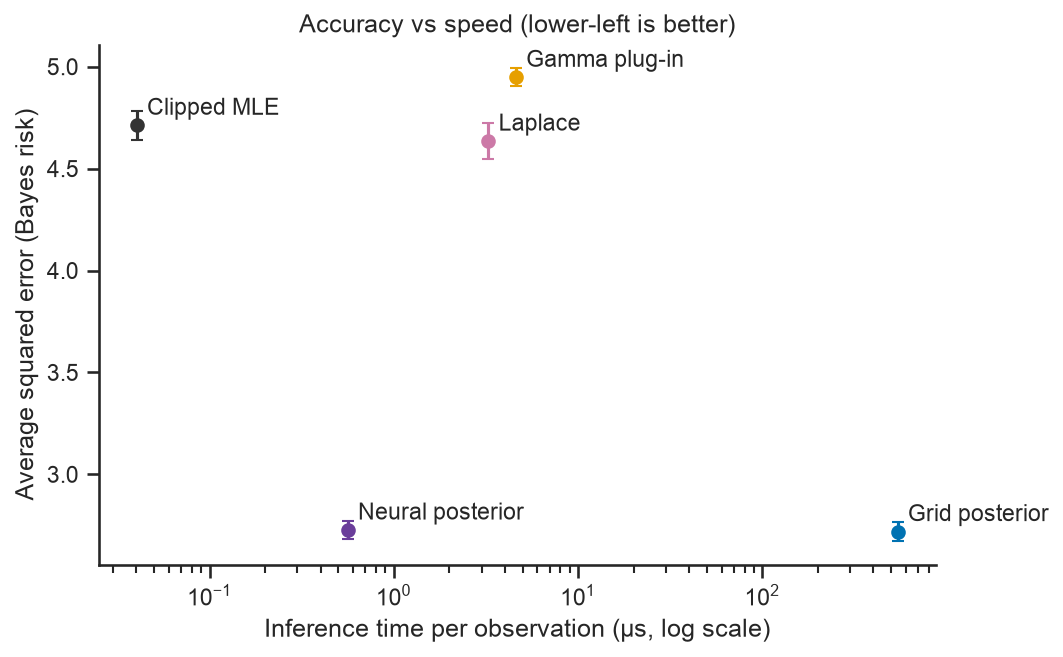

In [3]:
rows = [{'estimator': item['description'],
         'squared Bayes risk ± SE': metric_string(item['bayes_risk']['squared']),
         'paired difference vs grid ± SE':
         metric_string(item['paired_vs_exact_grid']['squared_loss_difference'])
         if 'paired_vs_exact_grid' in item else '–',
         'inference µs/row': round(item['inference_us'], 3)} for item in A['methods'].values()]
display(pd.DataFrame(rows))
nn = A['methods']['amortized']['paired_vs_exact_grid']['excess_squared_risk']
print('Neural excess risk E[(d_NN - d_grid)^2]:', metric_string(nn))
show_saved('path_a_pareto.png')

A low prior-averaged risk need not imply a low worst-case risk. The prior puts little
weight on strong sources. The Laplace approximation is expanded in $\mu$, where the
log-uniform prior adds a $-\log\mu$ term to the log posterior. This term can make the lower
prior cutoff $\mu=0.1$ the highest point, so the approximation piles its mass there. The
resulting spurious mode inflates the risk for most signals above about 2, at every
background; expanding in $\log\mu$, where the prior is flat, is the natural fix.

SBC checks posterior calibration averaged over the reality prior, and all four methods use
this same reference and the same 1,000 data sets. Gamma's rejection comes mainly from its
prior: it has no point mass at zero, so it ranks every $\mu=0$ truth at 0. Laplace's comes
from its spurious mode. SBC is a weak test of the neural posterior; the direct comparison
with the exact posterior printed below is stronger, and the paired coverage comparison in
part 5 shows a small deficit at strong signals that SBC does not detect.

In [4]:
display(pd.DataFrame([{'method': item['description'],
                      'max squared risk on b=3 ± pointwise SE':
                      metric_string(item['max_grid_risk_common_slice']['squared']),
                      'at theta': item['max_grid_risk_common_slice']['theta'],
                      'max over own slices':
                      metric_string(item['max_grid_risk']['squared']),
                      'SBC p-value':
                      A['diagnostics']['sbc'].get(name, {}).get('chi_square_p_value')}
                     for name, item in A['methods'].items()]))
print('The grid posterior risk uses only b=3; cheap methods also use b=1 and b=10.')
print('The selected point SE does not include uncertainty from maximizing over a grid.')
kl = A['diagnostics']['neural_vs_exact_posterior']
print('Neural vs exact posterior: mean KL', metric_string(kl['kl_exact_to_neural']),
      'nats | 95th percentile', round(kl['kl_quantile_0.95'], 3),
      '| variance correlation', round(kl['variance_correlation'], 3))

,method,max squared risk on b=3 ± pointwise SE,at theta,max over own slices,SBC p-value
0,Grid posterior,18.2502 ± 0.2844,"[10.0, 3.0, 1.0]",18.2502 ± 0.2844,0.223529
1,Gamma plug-in,11.0353 ± 0.1655,"[10.0, 3.0, 1.0]",16.6502 ± 0.2012,0.000000
2,Laplace,25.8328 ± 0.5347,"[10.0, 3.0, 1.0]",63.7579 ± 0.6945,0.000000
3,Neural posterior,19.0768 ± 0.2918,"[10.0, 3.0, 1.0]",26.9815 ± 0.3345,0.097156
4,Clipped MLE,7.5276 ± 0.1296,"[6.0, 3.0, 1.0]",11.0450 ± 0.1826,NaN


The grid posterior risk uses only b=3; cheap methods also use b=1 and b=10.
The selected point SE does not include uncertainty from maximizing over a grid.
Neural vs exact posterior: mean KL 0.0186 ± 0.0003 nats | 95th percentile 0.062 | variance correlation 0.994


## 4. Path B: the FC belt and coverage

A confidence procedure targets $P_\theta\{\mu\in I(X)\}\geq 1-\alpha$ at each fixed
parameter, with $\alpha=0.1$. Feldman–Cousins (FC) orders counts by a likelihood ratio
restricted to the physical signal domain. The count that crosses the target is included.
As in the published tables, each upper endpoint is made non-increasing in $b$ for every
count, and endpoints are rounded outward to the next grid node. Core coverage uses exact
Poisson sums; discreteness leads to overcoverage. Coverage at the 0.01 construction nodes
holds by construction, so FC and core WALDO are also checked on a 0.001 scan between them.

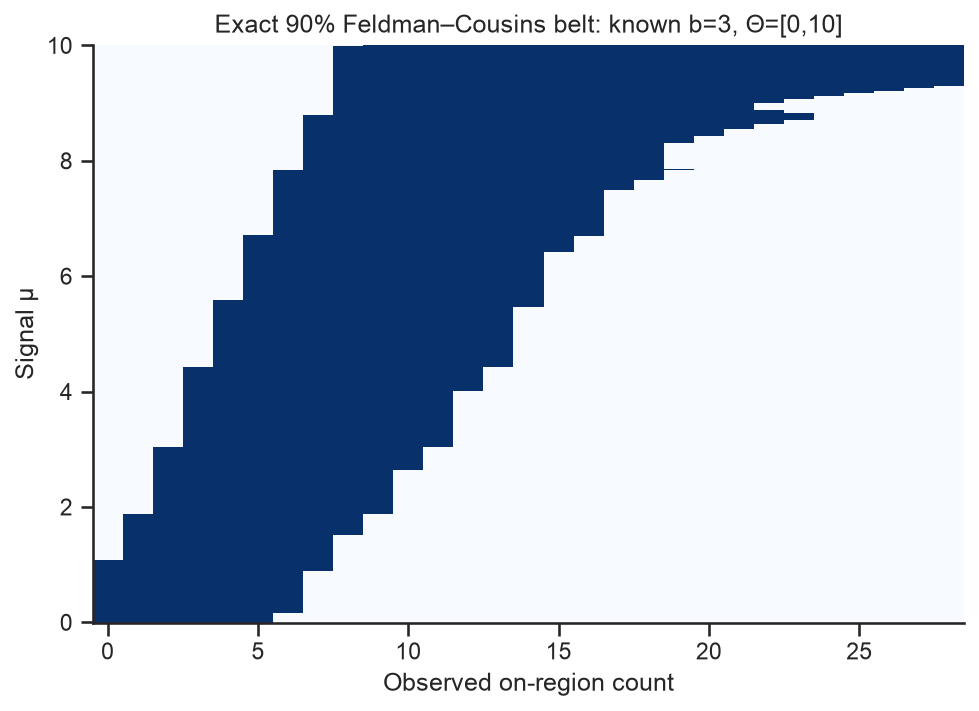

In [5]:
show_saved('path_b_fc_belt.png')

In the full case, profile LR and WALDO use independently simulated critical values,
maximized over seven backgrounds and five efficiencies. WALDO calls the trained Path A
model through `moments(x)` and uses its conditional posterior variance.
Before inversion, each coarse critical value (signal step 0.1) is raised to the maximum of
itself and its two neighbours, and this envelope is interpolated linearly onto a signal grid
with step 0.01. This is a numerical convention, not a proof of coverage between nodes.
Coverage and length refer to inclusive hulls; raw sets are diagnosed too.

,method,case,checked points,minimum coverage ± pointwise SE,tolerance,passes checked grid
0,FC,core,10001,0.9001 ± 0.0000,0.005,True
1,Naive Wald,core,104,0.7889 ± 0.0000,0.005,False
2,Central Neyman,core,104,0.9031 ± 0.0000,0.005,True
3,Upper limit,core,104,0.9002 ± 0.0000,0.005,True
4,Flat credible,core,104,0.0000 ± 0.0000,0.005,False
5,WALDO (exact posterior),core,10001,0.9001 ± 0.0000,0.005,True
6,Profile LR,full,728,0.8942 ± 0.0049,0.015,True
7,WALDO,full,728,0.8992 ± 0.0048,0.015,True
8,Naive Wald,full,728,0.4994 ± 0.0025,0.015,False


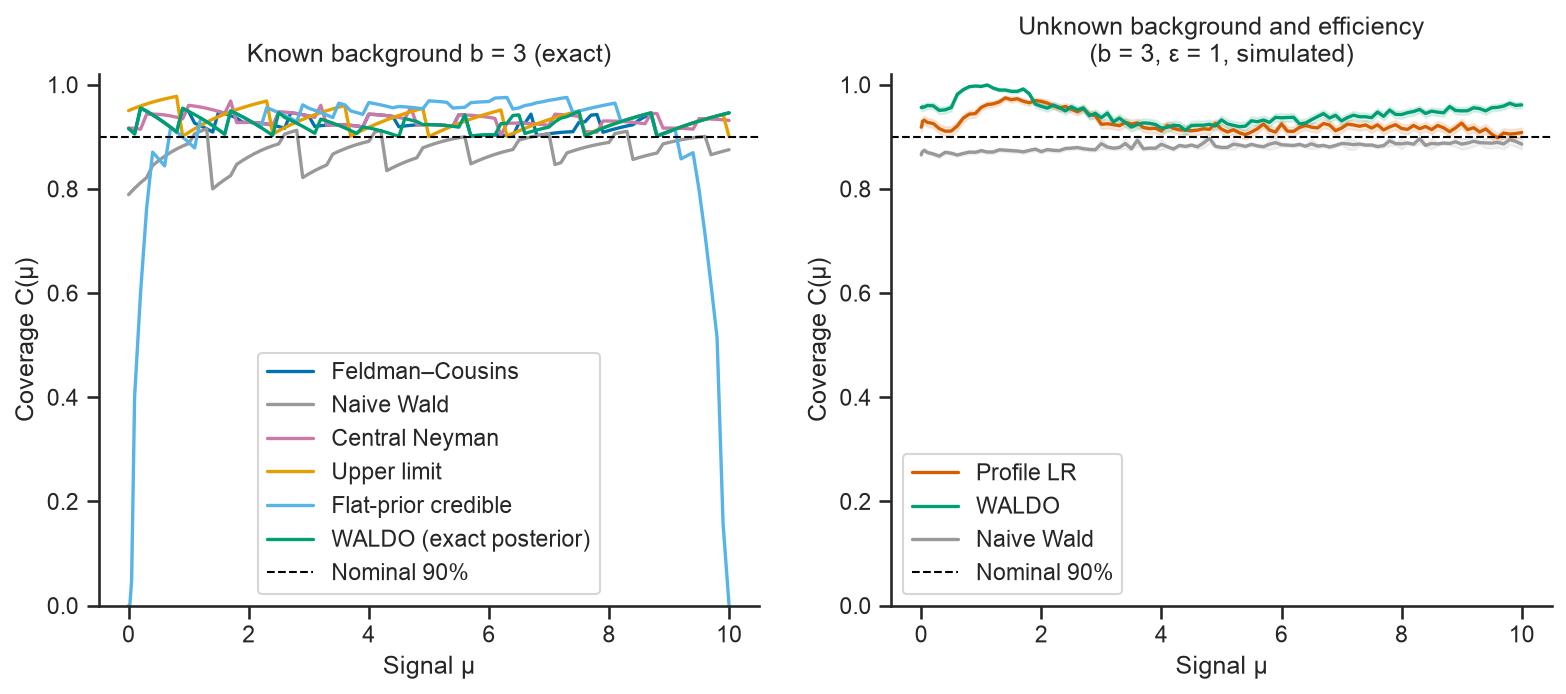

Profile LR maximum raw disconnected rate: 0.054
WALDO maximum raw disconnected rate: 0.02875
FC Tables IV-V entries checked: 420 | within tolerance: 420 | largest difference: 0.005 | plain construction within tolerance: 361
coverage: 728 points, 707 on calibration nodes
efficiency_variations: 2912 points, 2828 on calibration nodes
off_grid_coverage: 45 points, 0 on calibration nodes
random_box: 300 points, 0 on calibration nodes


,method,grid,reported minimum ± SE,"re-estimated there (40,000 toys)",lowest of 5 re-estimates
0,Profile LR,coverage,0.8942 ± 0.0049,0.9111 ± 0.0014,0.9081 ± 0.0014
1,Profile LR,efficiency_variations,0.8928 ± 0.0049,0.9067 ± 0.0015,0.8986 ± 0.0015
2,WALDO,coverage,0.8992 ± 0.0048,0.9026 ± 0.0015,0.9026 ± 0.0015
3,WALDO,efficiency_variations,0.8905 ± 0.0049,0.9001 ± 0.0015,0.9001 ± 0.0015


WALDO model SHA-256: 6bc472ceddc24e6e95ee57b21511d0e5f5321465e72a7de2320ea4bb1c6179a0


In [6]:
rows = []
for check in B_summary['diagnostics']['coverage_check']:
    rows.append({'method': B['methods'][check['method']]['label'],
                 'case': B['methods'][check['method']]['mode'],
                 'checked points': check['domain']['n_points'],
                 'minimum coverage ± pointwise SE':
                 metric_string(check['minimum_coverage']['coverage']),
                 'tolerance': check['tolerance'], 'passes checked grid': check['passed']})
display(pd.DataFrame(rows))
show_saved('path_b_coverage.png')
for name in ('profile_lr_full', 'waldo_full'):
    rows = B['diagnostics']['set_diagnostics'][name]['initial_toys']
    print(B['methods'][name]['label'], 'maximum raw disconnected rate:',
          max(r['disconnected_rate']['value'] for r in rows))
fc_checks = B_summary['diagnostics']['fc_reference_checks']
print('FC Tables IV-V entries checked:', fc_checks['n_entries'],
      '| within tolerance:', fc_checks['n_passed'],
      '| largest difference:', round(fc_checks['maximum_error'], 3),
      '| plain construction within tolerance:', fc_checks['plain_n_passed'])
for grid, counts in B_summary['diagnostics']['calibration_node_overlap'].items():
    print(f"{grid}: {counts['n_points']} points, {counts['mu_and_nuisance_on_node']} "
          'on calibration nodes')
rows = []
for name, grids in B_summary['diagnostics']['reestimated_minima'].items():
    for grid, record in grids.items():
        lowest = min(record['points'], key=lambda p: p['original']['value'])
        rows.append({'method': B['methods'][name]['label'], 'grid': grid,
                     'reported minimum ± SE': metric_string(lowest['original']),
                     're-estimated there (40,000 toys)': metric_string(lowest['reestimated']),
                     'lowest of 5 re-estimates':
                     metric_string(record['minimum_reestimated']['coverage'])})
display(pd.DataFrame(rows))
print('WALDO model SHA-256:', B['diagnostics']['waldo_model']['sha256'])

## 5. Reconciliation: evaluate each method under the other criterion

A credible interval has a posterior-probability interpretation. Its fixed-parameter
coverage is a measured result. The equal-tailed interval runs from the 5% to the 95%
posterior quantile. Because of the point mass at zero, 92.7% of the intervals start at 0 and
hold at least 95% of the posterior, so the intervals hold 94.7% of the posterior on average.
Their prior-averaged coverage, 94.6%, matches this: it is the calibration that calibrated
Bayes (Rubin 1984) asks of a correct posterior, not over-coverage.

The next plot compares Bayes credible intervals with calibrated confidence hulls on the
common $b=3,\varepsilon=1$ slice. Bands show two pointwise MC SE. For signals from 3 to 8.5
the grid-posterior interval covers only 79–82% of the time (MC SE about 0.006), although the
intervals there hold 92–94% of the posterior: averages hide fixed-parameter failures. The
prior expects weak signals, so a strong true signal pulls the interval toward low values.
The upper boundary has no prior atom: equal-tail credible intervals exclude $\mu=10$,
giving zero endpoint coverage here.

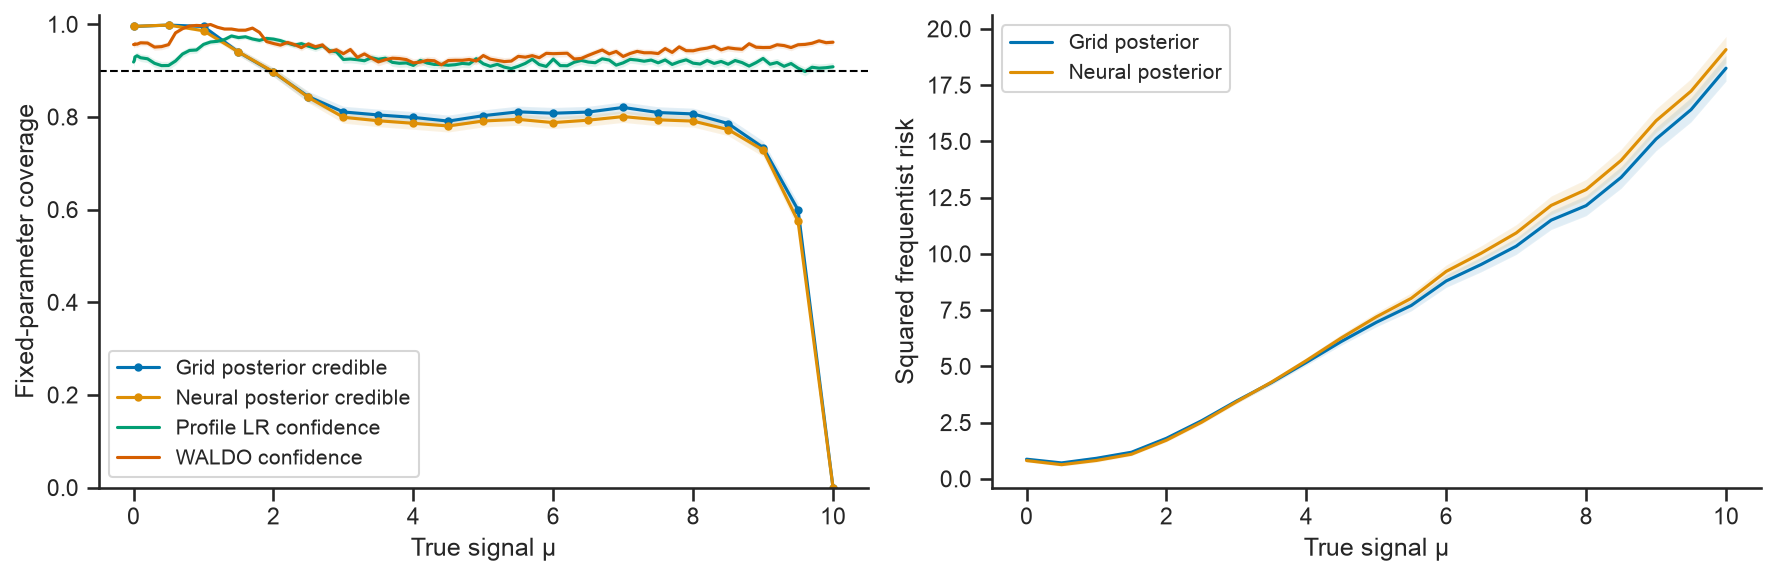

,mu,grid coverage ± SE,grid posterior content,neural minus grid coverage ± paired SE
0,0.0,0.9952 ± 0.0011,0.9500,0.0003 ± 0.0002
1,0.5,0.9982 ± 0.0007,0.9497,0.0000 ± 0.0000
2,1.0,0.9952 ± 0.0011,0.9491,-0.0092 ± 0.0017
3,1.5,0.9400 ± 0.0038,0.9487,0.0003 ± 0.0013
4,2.0,0.8962 ± 0.0048,0.9476,0.0010 ± 0.0017
5,2.5,0.8438 ± 0.0057,0.9459,-0.0018 ± 0.0018
6,3.0,0.8107 ± 0.0062,0.9442,-0.0115 ± 0.0021
7,3.5,0.8043 ± 0.0063,0.9425,-0.0125 ± 0.0021
8,4.0,0.7990 ± 0.0063,0.9402,-0.0127 ± 0.0020
9,4.5,0.7910 ± 0.0064,0.9380,-0.0105 ± 0.0019


Prior-averaged coverage 0.9463 ± 0.0016 | mean posterior content 0.9466 ± 0.0001 | share starting at 0 0.9270 ± 0.0018


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in ('exact_grid', 'amortized'):
    rows = [row for row in A['methods'][name]['coverage'] if row['theta'][1:] == [3., 1.]]
    axes[0].plot([r['theta'][0] for r in rows], [r['coverage']['value'] for r in rows],
                 marker='.', label=A['methods'][name]['description']+' credible')
    values = np.array([r['coverage']['value'] for r in rows])
    errors = np.array([r['coverage']['mc_se'] for r in rows])
    axes[0].fill_between([r['theta'][0] for r in rows],
                         values-2*errors, values+2*errors, alpha=.12)
    risks = [r for r in A['methods'][name]['frequentist_risk'] if r['theta'][1:] == [3., 1.]]
    axes[1].plot([r['theta'][0] for r in risks], [r['squared']['value'] for r in risks],
                 label=A['methods'][name]['description'])
    values = np.array([r['squared']['value'] for r in risks])
    errors = np.array([r['squared']['mc_se'] for r in risks])
    axes[1].fill_between([r['theta'][0] for r in risks],
                         values-2*errors, values+2*errors, alpha=.12)
for name in ('profile_lr_full', 'waldo_full'):
    rows = [r for r in B['methods'][name]['coverage'] if r['theta'][1:] == [3., 1.]]
    axes[0].plot([r['theta'][0] for r in rows], [r['coverage']['value'] for r in rows],
                 label=B['methods'][name]['label']+' confidence')
    values = np.array([r['coverage']['value'] for r in rows])
    errors = np.array([r['coverage']['mc_se'] for r in rows])
    axes[0].fill_between([r['theta'][0] for r in rows],
                         values-2*errors, values+2*errors, alpha=.12)
axes[0].axhline(.9, color='black', linestyle='--', linewidth=1)
axes[0].set(xlabel='True signal µ', ylabel='Fixed-parameter coverage', ylim=(0, 1.02))
axes[1].set(xlabel='True signal µ', ylabel='Squared frequentist risk')
for ax in axes:
    ax.legend(fontsize=10)
fig.tight_layout()
plt.show()
grid_rows = {tuple(r['theta']): r for r in A['methods']['exact_grid']['coverage']}
display(pd.DataFrame([
    {'mu': r['theta'][0],
     'grid coverage ± SE': metric_string(grid_rows[tuple(r['theta'])]['coverage']),
     'grid posterior content': round(
         grid_rows[tuple(r['theta'])]['posterior_content']['value'], 4),
     'neural minus grid coverage ± paired SE': metric_string(r['coverage_difference'])}
    for r in A['methods']['amortized']['paired_coverage_vs_exact_grid']]))
summary = A['methods']['exact_grid']['interval_summary']
print('Prior-averaged coverage', metric_string(summary['coverage']),
      '| mean posterior content', metric_string(summary['posterior_content']),
      '| share starting at 0', metric_string(summary['lower_at_zero_rate']))

For an interval procedure, point-estimation loss needs an action. We use the **hull
midpoint**, with clipped-MLE fallback for an empty hull. This is a stated convention;
interval length is never called Bayes risk. Core and full risks have different nuisance
models and must be compared within their own model. The natural frequentist point estimator
is the clipped MLE from part 3, not a set midpoint.

In [8]:
rows = []
for item in B['methods'].values():
    rows.append({'procedure': item['label'], 'case': item['mode'],
                 'midpoint squared Bayes risk ± SE': metric_string(item['bayes_risk']['squared']),
                 'prior-averaged hull coverage ± SE':
                 metric_string(item['interval_summary']['coverage']),
                 'expected length ± SE':
                 metric_string(item['interval_summary']['expected_length'])})
display(pd.DataFrame(rows))
print('Compare full-case midpoint risks with the full-case posterior-mean risks in part 3.')

,procedure,case,midpoint squared Bayes risk ± SE,prior-averaged hull coverage ± SE,expected length ± SE
0,FC,core,4.9802 ± 0.0398,0.9254 ± 0.0019,5.1420 ± 0.0148
1,Naive Wald,core,3.4604 ± 0.0347,0.8366 ± 0.0026,4.1638 ± 0.0198
2,Central Neyman,core,5.7840 ± 0.0431,0.9295 ± 0.0018,5.6170 ± 0.0179
3,Upper limit,core,4.3004 ± 0.0365,0.9476 ± 0.0016,5.0957 ± 0.0209
4,Flat credible,core,6.6440 ± 0.0400,0.5810 ± 0.0035,5.6846 ± 0.0097
5,WALDO (exact posterior),core,5.4132 ± 0.0394,0.9267 ± 0.0018,5.4319 ± 0.0112
6,Profile LR,full,6.6676 ± 0.0501,0.9287 ± 0.0018,5.8470 ± 0.0165
7,WALDO,full,6.3301 ± 0.0489,0.9568 ± 0.0014,5.9176 ± 0.0193
8,Naive Wald,full,5.2577 ± 0.0478,0.8739 ± 0.0023,5.0308 ± 0.0220


Compare full-case midpoint risks with the full-case posterior-mean risks in part 3.


The analysis prior may be wrong. All bars below use the same reality-prior data but change
the inference prior. A shifted Gamma prior is especially costly near the zero atom. The table
gives paired differences on the same draws. With a flat or diffuse Gamma prior, the posterior
mean loses to the clipped MLE: the Bayesian advantage needs the right prior, while the
frequentist guarantee does not.

Calibration also needs the full nuisance scope: calibrating at $\varepsilon=1$ only
shows what can go wrong when efficiency variation is ignored. The random points are off
every calibration node, so they compare the full calibration and the $\varepsilon=1$-only
ablation like with like.

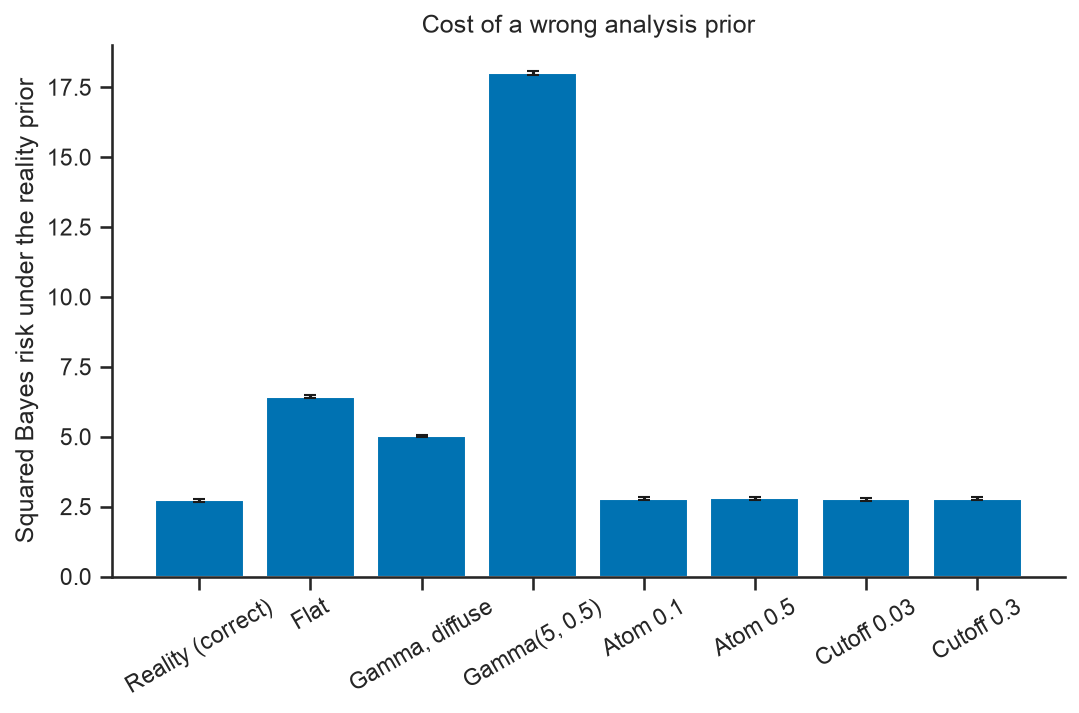

,analysis prior,squared Bayes risk ± SE,vs reality prior (paired),vs clipped MLE (paired)
0,reality,2.7192 ± 0.0462,–,-1.9937 ± 0.0577
1,flat,6.4282 ± 0.0504,3.7090 ± 0.0536,1.7153 ± 0.0468
2,gamma_diffuse,5.0260 ± 0.0419,2.3068 ± 0.0406,0.3131 ± 0.0453
3,gamma_shifted,18.0211 ± 0.0770,15.3019 ± 0.0956,13.3082 ± 0.0870
4,zero_mass_0.1,2.7876 ± 0.0426,0.0684 ± 0.0066,-1.9253 ± 0.0539
5,zero_mass_0.5,2.7926 ± 0.0512,0.0734 ± 0.0080,-1.9203 ± 0.0635
6,cutoff_0.03,2.7543 ± 0.0496,0.0351 ± 0.0056,-1.9586 ± 0.0617
7,cutoff_0.3,2.7880 ± 0.0426,0.0688 ± 0.0072,-1.9249 ± 0.0532


,method,random-point minimum ± SE,confirmed failures,passes
0,Profile LR,0.8970 ± 0.0048,0,True
1,WALDO,0.8950 ± 0.0048,0,True
2,Profile LR (calibrated at ε = 1 only),0.8550 ± 0.0018,3,False
3,WALDO (calibrated at ε = 1 only),0.8701 ± 0.0017,5,False


,method,box sensitivity minimum ± SE,passes
0,Profile LR (efficiency box),0.8928 ± 0.0049,True
1,WALDO (efficiency box),0.8905 ± 0.0049,True
2,Naive Wald (efficiency box),0.4847 ± 0.0025,False
3,Profile LR (calibrated at ε = 1 only),0.8317 ± 0.0019,False
4,WALDO (calibrated at ε = 1 only),0.8482 ± 0.0018,False


In [9]:
show_saved('path_a_prior_sensitivity.png')
rows = []
for name, item in A['diagnostics']['prior_sensitivity'].items():
    paired = item.get('paired', {})
    rows.append({'analysis prior': name,
                 'squared Bayes risk ± SE': metric_string(item['bayes_risk']['squared']),
                 'vs reality prior (paired)':
                 metric_string(paired['vs_reality']['squared_loss_difference'])
                 if 'vs_reality' in paired else '–',
                 'vs clipped MLE (paired)':
                 metric_string(paired['vs_clipped_mle']['squared_loss_difference'])})
display(pd.DataFrame(rows))
rows = []
for check in B_summary['diagnostics']['random_box_check']:
    label = check['method'].replace('_eps0_only', '')
    rows.append({'method': B['methods'][label]['label']
                 + (' (calibrated at ε = 1 only)' if label != check['method'] else ''),
                 'random-point minimum ± SE':
                 metric_string(check['minimum_coverage']['coverage']),
                 'confirmed failures': check['flagged_count_after_reruns'],
                 'passes': check['passed']})
display(pd.DataFrame(rows))
rows = []
for check in B['diagnostics']['efficiency_coverage_check']:
    rows.append({'method': B['methods'][check['method']]['label'] + ' (efficiency box)',
                 'box sensitivity minimum ± SE':
                 metric_string(check['minimum_coverage']['coverage']), 'passes': check['passed']})
for check in B['diagnostics']['eps0_ablation']['coverage_check']:
    rows.append({'method': B['methods'][check['method']]['label']
                 + ' (calibrated at ε = 1 only)',
                 'box sensitivity minimum ± SE':
                 metric_string(check['minimum_coverage']['coverage']),
                 'passes': check['passed']})
display(pd.DataFrame(rows))

## 6. Takeaways

| Need | Suitable procedure | Evidence here | Scope and limitation |
|---|---|---|---|
| Low average squared loss | Reality-prior posterior mean; fast neural approximation | Bayes risk with paired MC SE | Needs the right prior: with a flat prior the clipped MLE does better; the posterior median serves absolute loss |
| Known-background confidence coverage | Restricted FC with its b-correction | Exact sums on a fine signal scan and all 420 published table entries | Discrete counts; upper bound belongs in construction |
| Full-case confidence coverage | Profile LR or WALDO with the neural posterior | Fresh toys over a bounded nuisance box, including random points off the calibration nodes | Pass rule detects only clear shortfalls (below about 0.885); not a continuous-domain theorem |
| Fast approximate posterior | Neural model | Risk, compute cost, SBC and a direct comparison with the exact posterior | SBC missed a small fixed-signal coverage deficit |
| Robustness to a wrong prior | Cross-criterion checks and prior sensitivity | Risk curves and coverage curves | No single winner under all losses and domains; one simulator |

Calibration toy error, finite grids, quadrature error, and pointwise MC error are different.
The minimum selected over many points is biased low; fresh re-estimates of the lowest points
are shown in part 4. The nuisance box covers only part of the unbounded efficiency prior, and
no guarantee is claimed outside it.
Wald and equal-tail credible endpoint failures are reported on purpose, as teaching results.
Both results files also store plain-English notes on scope and limitations under the key
`notes`; the points above summarise them.

In [10]:
print('Recorded runtimes: Path A', round(A['runtime_seconds'], 2), 's; Path B',
      round(B['runtime_seconds'], 2), 's')
print('Main calibration grid:', len(B['diagnostics']['calibration']['mu_grid']), 'signal nodes ×',
      len(B['diagnostics']['calibration']['nuisance_grid']), 'nuisance nodes')

Recorded runtimes: Path A 149.64 s; Path B 367.14 s
Main calibration grid: 101 signal nodes × 35 nuisance nodes
